In [42]:
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import datasets, layers, models
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

In [43]:
(X_train, y_train), (X_test, y_test) = datasets.cifar10.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


In [44]:
y_train = y_train.flatten()
y_test = y_test.flatten()

In [45]:
print(X_train.shape)
print(y_train.shape)

(50000, 32, 32, 3)
(50000,)


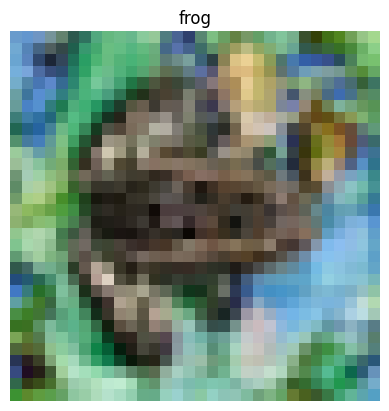

In [46]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

plt.imshow(X_train[200])
plt.title(class_names[y_train[200]])
plt.axis('off')
plt.show()

In [47]:
resize = layers.Resizing(224, 224)

# VGG16

In [48]:

base_model_vgg = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

In [49]:
for layer in base_model_vgg.layers:
    layer.trainable = False

In [50]:
vgg_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    
    # resizing each batch
    layers.Resizing(224, 224),

    base_model_vgg,

    # imageNet preprocessing for VGG16
    layers.Lambda(vgg_preprocess),

    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

In [51]:
vgg_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

vgg_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_7 (Resizing)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_2 (Lambda)               │ (None, 7, 7, 3)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 3)              │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,718,282 (56.15 MB)

 Trainable params: 3,594 (14.04 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [52]:
history_vgg = vgg_model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 282s 223ms/step - accuracy: 0.1002 - loss: 15.0433 - val_accuracy: 0.1089 - val_loss: 2.3262
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 274s 219ms/step - accuracy: 0.1447 - loss: 2.6500 - val_accuracy: 0.2150 - val_loss: 2.1765
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 274s 219ms/step - accuracy: 0.1835 - loss: 2.1982 - val_accuracy: 0.2151 - val_loss: 2.1630
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 275s 220ms/step - accuracy: 0.1878 - loss: 2.1837 - val_accuracy: 0.2191 - val_loss: 2.1539
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 275s 220ms/step - accuracy: 0.1923 - loss: 2.1706 - val_accuracy: 0.2056 - val_loss: 2.1448


In [53]:
vgg_model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 55s 175ms/step - accuracy: 0.2041 - loss: 2.1391


[2.1390717029571533, 0.20409999787807465]

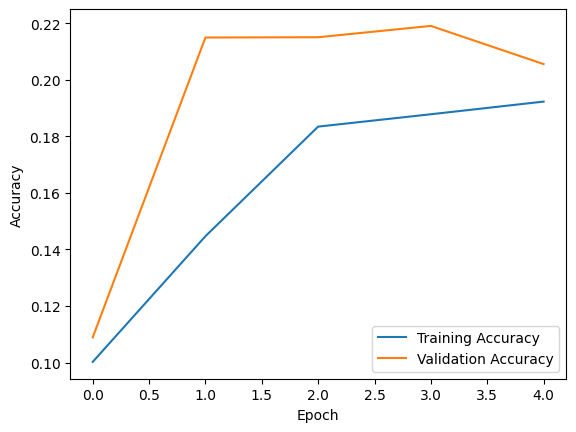

In [54]:
plt.plot(history_vgg.history['accuracy'], label='Training Accuracy')
plt.plot(history_vgg.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# ResNet50

In [55]:
#ResNet50

#load ResNet50
base_model_resnet = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# freeze base layers
for layer in base_model_resnet.layers:
    layer.trainable = False

In [56]:
#build model
resnet_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    
    # resizing each batch
    layers.Resizing(224, 224),

    # imageNet preprocessing for ResNet50
    layers.Lambda(resnet_preprocess),

    base_model_resnet,

    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

In [57]:
#compile model
resnet_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

resnet_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_8 (Resizing)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_3 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,114,826 (91.99 MB)

 Trainable params: 527,114 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [58]:
#train
history_resnet = resnet_model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 144s 107ms/step - accuracy: 0.7787 - loss: 0.6545 - val_accuracy: 0.8840 - val_loss: 0.3393
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 127s 102ms/step - accuracy: 0.8727 - loss: 0.3760 - val_accuracy: 0.8930 - val_loss: 0.3036
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 127s 101ms/step - accuracy: 0.8897 - loss: 0.3209 - val_accuracy: 0.9020 - val_loss: 0.2793
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 127s 102ms/step - accuracy: 0.9029 - loss: 0.2844 - val_accuracy: 0.9076 - val_loss: 0.2656
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 127s 102ms/step - accuracy: 0.9109 - loss: 0.2560 - val_accuracy: 0.9053 - val_loss: 0.2711


In [59]:
#evaluate
resnet_model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 25s 81ms/step - accuracy: 0.9053 - loss: 0.2811


[0.2810976207256317, 0.9053000211715698]

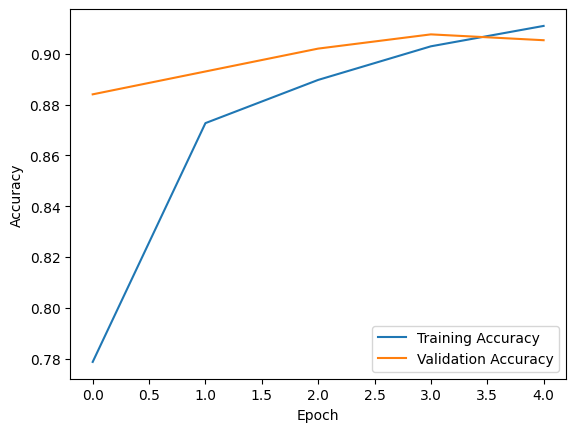

In [60]:
#plot
plt.plot(history_resnet.history['accuracy'], label='Training Accuracy')
plt.plot(history_resnet.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Finetuning

In [61]:
#fine tune vgg 16

# unfreeze last 4 layers of VGG16
for layer in base_model_vgg.layers[-4:]:
    layer.trainable = True

# compile again with smaller learning rate
vgg_model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# fine tune
vgg_model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/3
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 314s 248ms/step - accuracy: 0.3541 - loss: 1.6921 - val_accuracy: 0.5380 - val_loss: 1.3260
Epoch 2/3
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 308s 246ms/step - accuracy: 0.4645 - loss: 1.3796 - val_accuracy: 0.5987 - val_loss: 1.1590
Epoch 3/3
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 308s 246ms/step - accuracy: 0.5231 - loss: 1.2329 - val_accuracy: 0.6417 - val_loss: 1.0217


In [62]:
vgg_loss, vgg_accuracy = vgg_model.evaluate(X_test, y_test)

print("VGG16 Test Loss:", vgg_loss)
print("VGG16 Test Accuracy:", vgg_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 55s 176ms/step - accuracy: 0.6362 - loss: 1.0309
VGG16 Test Loss: 1.0309462547302246
VGG16 Test Accuracy: 0.6362000107765198


In [63]:
#fine tune resnet 50

# unfreeze last 10 layers
for layer in base_model_resnet.layers[-10:]:
    layer.trainable = True

# compile again with smaller learning rate
resnet_model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# fine tune
resnet_model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/3
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 158s 117ms/step - accuracy: 0.9219 - loss: 0.2302 - val_accuracy: 0.9166 - val_loss: 0.2385
Epoch 2/3
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 139s 111ms/step - accuracy: 0.9349 - loss: 0.1914 - val_accuracy: 0.9196 - val_loss: 0.2268
Epoch 3/3
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 139s 111ms/step - accuracy: 0.9481 - loss: 0.1575 - val_accuracy: 0.9236 - val_loss: 0.2203


In [64]:
resnet_loss, resnet_accuracy = resnet_model.evaluate(X_test, y_test)

print("ResNet50 Test Loss:", resnet_loss)
print("ResNet50 Test Accuracy:", resnet_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 25s 81ms/step - accuracy: 0.9199 - loss: 0.2389
ResNet50 Test Loss: 0.23887741565704346
ResNet50 Test Accuracy: 0.9199000000953674


In [65]:
print("VGG16 Test Accuracy:", vgg_accuracy)
print("ResNet50 Test Accuracy:", resnet_accuracy)

VGG16 Test Accuracy: 0.6362000107765198
ResNet50 Test Accuracy: 0.9199000000953674
